# SunSim vs SORCE/TIM, TSIS-1 and HARPS-N (10 years), and injection of planets

In [17]:
import os

import numpy as np
import matplotlib.pyplot as plt

from sunsim import local_path, observations as obs
from sunsim.residuals import ResidualAnalysis

plt.rcParams.update({
    "figure.figsize": (15, 9),
    "font.size": 15,
    "axes.labelsize": 15,
    "axes.titlesize": 15,
    "xtick.labelsize": 15,
    "ytick.labelsize": 15,
    "legend.fontsize": 13,
    "axes.linewidth": 0.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "lines.linewidth": 1.5,
    "lines.markersize": 3,
})

## Parameters

In [18]:
SIM_RV = os.path.join(local_path('personal_data'), 'rv-15.txt')
SIM_LC = os.path.join(local_path('personal_data'), 'lc-15.txt')

ORIGIN = '2015-07-18'                # t = 0 of the simulation
FIRST, LAST = '2015-07-18', '2024-01-28'
# FIRST, LAST = '2015-09-01', '2015-11-30'
# FIRST, LAST = '2021-05-01', '2021-07-31'
FIRST, LAST = '2015-07-18', '2018-07-18'

FIGURES =  "/Users/sophiestucki/Documents/rv_opt/figures/final/"                       # folder where the figures are saved (None: not saved)

INJECT = False                        # False: only the comparison; True: also periodograms, wavelets and injection of planets
PERIODS = np.linspace(5, 500, 10)    # injected periods [days]
AMPLITUDES = np.linspace(0.1, 0.5, 21)   # injected semi-amplitudes [m/s]
N_PHASES = 100                       # times of transit per period and semi-amplitude
FAP = 1e-3                           # detection threshold
PERIOD_TOL = 0.1                     # recovered period within 10 % of the injected one
ROTATION = 26                        # [days] detections at the rotation period instead of the planet
LC_OUTLIERS = [564]                  # [days since ORIGIN] simulated flux epochs removed from the photometry


def save(fig, name):
    if FIGURES:
        fig.savefig(os.path.join(FIGURES, name + '.pdf'), bbox_inches='tight', dpi=300)

## Data

In [19]:
t_s, rv_s = np.loadtxt(SIM_RV).T
_, lc_s = np.loadtxt(SIM_LC).T
window = (t_s >= obs.jd_of_date(FIRST) - obs.jd_of_date(ORIGIN)) & (t_s < obs.jd_of_date(LAST) - obs.jd_of_date(ORIGIN) + 1)
t_s, rv_s, lc_s = t_s[window], rv_s[window], lc_s[window]
lc_ok = ~np.isin(t_s, LC_OUTLIERS)
t_lc, lc_s = t_s[lc_ok], lc_s[lc_ok]

harps = obs.load_harpsn(local_path('harpsn_sun'), ORIGIN, end=LAST, t_start=FIRST)
sorce = obs.load_sorce(local_path('sorce_tsi'), ORIGIN, end=LAST, t_start=FIRST)
tsis = obs.load_tsis(local_path('tsis_tsi'), ORIGIN, end=LAST, t_start=FIRST)
cuts = obs.load_interventions(local_path('harpsn_interventions'), ORIGIN)

## Comparison

In [20]:
phot = [obs.compare_photometry(sorce, t_lc, lc_s), obs.compare_photometry(tsis, t_lc, lc_s)]
phot = [ph for ph in phot if ph['n'] > 0]
rv = obs.compare_rv(harps, t_s, rv_s, interventions=cuts)

obs.print_summary(phot, rv)
for ph, (off_obs, off_sim) in zip(phot, obs.photometry_offsets(phot)):
    print('%-10s offset obs %.1f ppm, sim %.1f ppm' % (ph['name'], off_obs, off_sim))

SORCE/TIM  1084 days  residuals: MAD    32.8 ppm  RMS    61.0 ppm   (observed: MAD   109.6  RMS   216.1 ppm)
TSIS-1      156 days  residuals: MAD    26.0 ppm  RMS    43.4 ppm   (observed: MAD    33.5  RMS    60.1 ppm)
  period  0:    11.5 ->    87.0  sim   75  obs   53  matched   52  shift    1  RMS 0.850 m/s
  period  1:    87.0 ->   257.0  sim  168  obs  103  matched  101  shift    0  RMS 0.819 m/s
  period  2:   257.0 ->   466.0  sim  206  obs  172  matched  170  shift    1  RMS 0.743 m/s
  period  3:   466.0 ->   633.0  sim  166  obs   86  matched   85  shift    1  RMS 0.663 m/s
  period  4:   633.0 ->   850.0  sim  215  obs  161  matched  159  shift    1  RMS 0.711 m/s
  period  5:   850.0 ->  1010.0  sim  159  obs   46  matched   45  shift   -1  RMS 0.729 m/s
  period  6:  1010.0 ->  1063.0  sim   53  obs   39  matched   38  shift    1  RMS 0.492 m/s
  period  7:  1063.0 ->  1096.5  sim   34  obs   31  matched   30  shift    1  RMS 0.740 m/s
RV          680 days  residuals: MAD 0

## TSI and RV

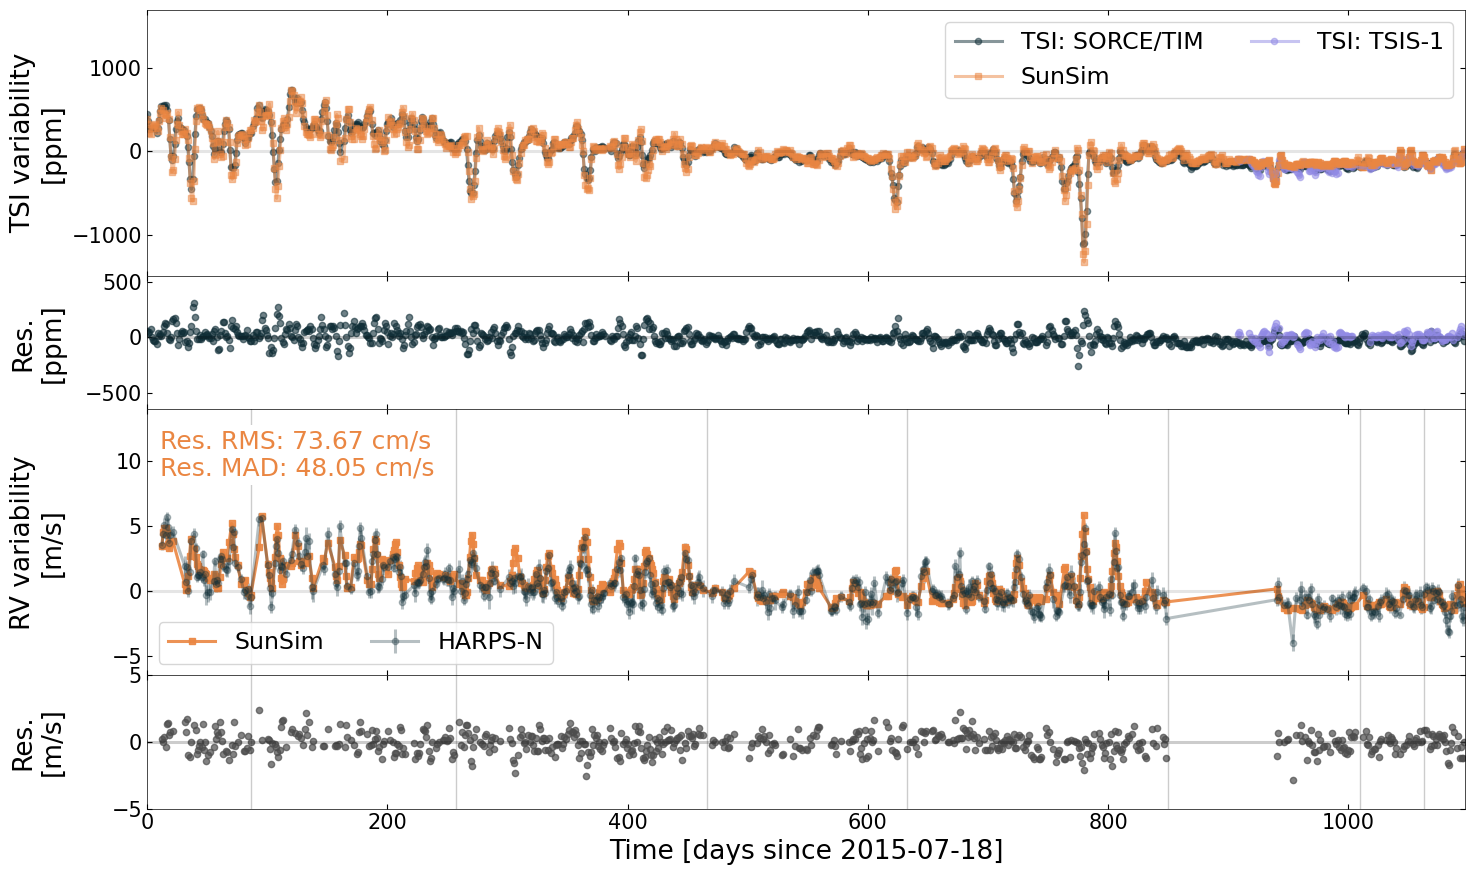

In [21]:
t0 = obs.jd_of_date(FIRST) - obs.jd_of_date(ORIGIN)
xlim = (t_s.min() - t0, t_s.max() + 1 - t0)

with plt.rc_context({'axes.labelsize': 19, 'legend.fontsize': 17, 'lines.linewidth': 2.2, 'lines.markersize': 4.5}):
    fig, (ax1, ax1r, ax2, ax2r) = plt.subplots(4, 1, sharex=True, gridspec_kw={'hspace': 0, 'height_ratios': [2, 1, 2, 1]})

    obs.plot_photometry_comparison(phot, ax1, ax1r, t0=t0, stats=False)
    ax1.set_ylim(-1500, 1700)
    ax1r.set_ylim(-650, 550)

    obs.plot_rv_comparison(rv, ax2, ax2r, t0=t0)
    ax2.set_ylim(-6.5, 14)
    ax2r.set_ylim(-5, 5)

    ax2r.set_xlim(*xlim)
    ax2r.set_xlabel('Time [days since %s]' % FIRST)
    for a in (ax1, ax1r, ax2, ax2r):
        a.set_ylabel(a.get_ylabel().replace(' [', '\n['))
    fig.align_ylabels([ax1, ax1r, ax2, ax2r])
    fig.tight_layout()
    save(fig, 'all_best_fit_{}_{}'.format(FIRST,LAST))
    plt.show()

## RV

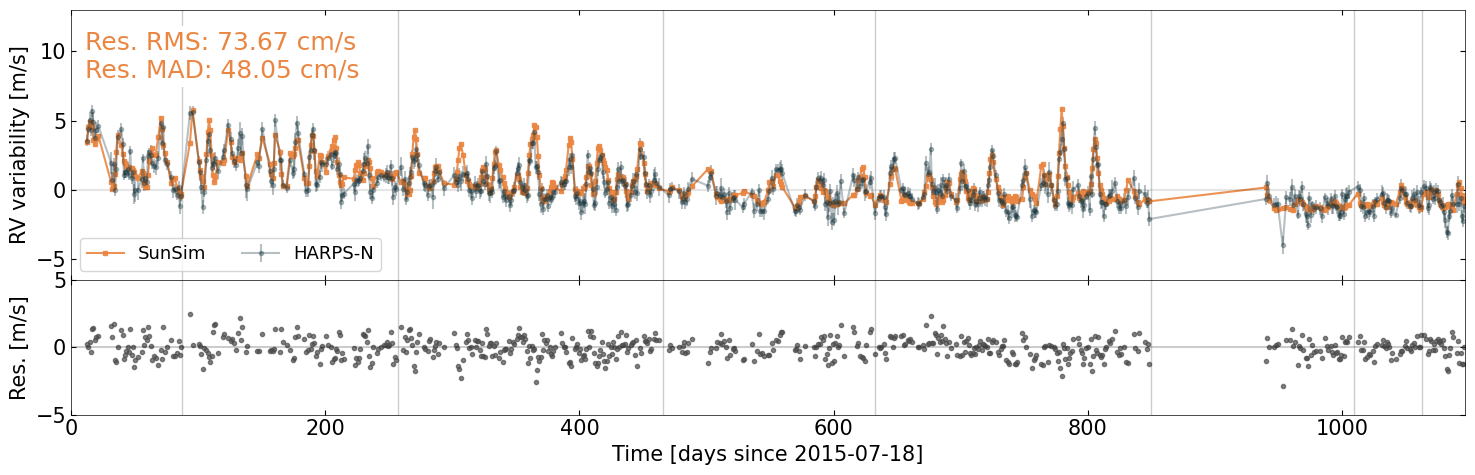

In [22]:
fig, (ax2, ax2r) = plt.subplots(2, 1, sharex=True, figsize=(15, 5), gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
obs.plot_rv_comparison(rv, ax2, ax2r, t0=t0)
ax2.set_ylim(-6.5, 13)
ax2r.set_ylim(-5, 5)
ax2r.set_xlim(*xlim)
ax2r.set_xlabel('Time [days since %s]' % FIRST)
fig.align_ylabels([ax2, ax2r])
fig.tight_layout()
save(fig, 'rv_only_{}_{}'.format(FIRST,LAST))
plt.show()

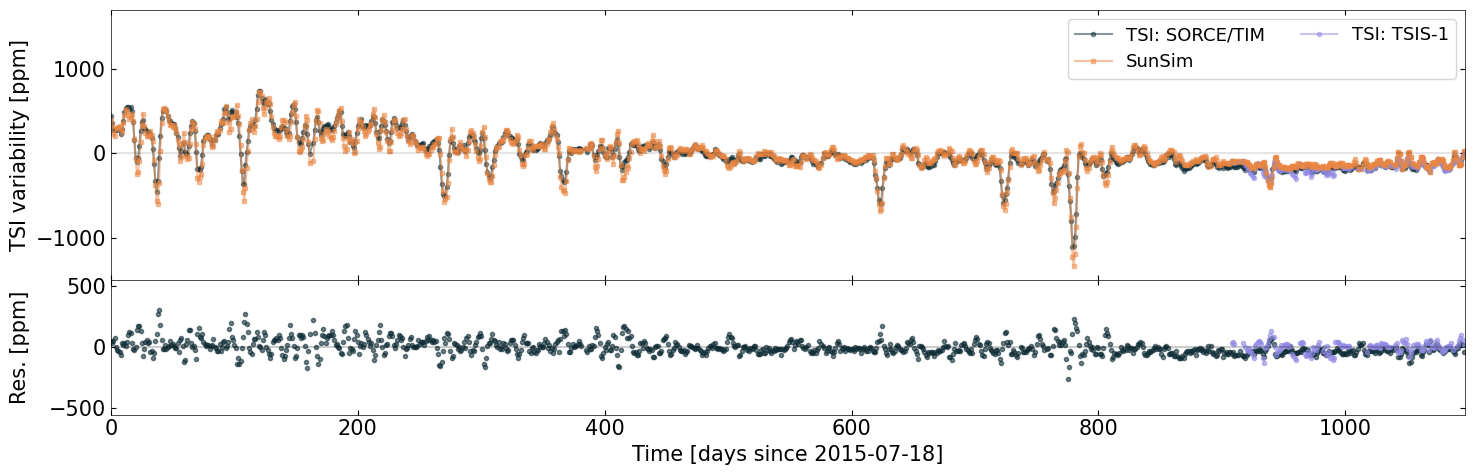

In [23]:
fig, (ax1, ax1r) = plt.subplots(2, 1, sharex=True, figsize=(15, 5), gridspec_kw={'hspace': 0, 'height_ratios': [2, 1]})
obs.plot_photometry_comparison(phot, ax1, ax1r, t0=t0, stats=False)
ax1.set_ylim(-1500, 1700)
ax1r.set_ylim(-550, 550)
ax1r.set_xlim(*xlim)
ax1r.set_xlabel('Time [days since %s]' % FIRST)
fig.align_ylabels([ax1, ax1r])
fig.tight_layout()
save(fig, 'phot_only_{}_{}'.format(FIRST,LAST))
plt.show()

## Two 3-month windows

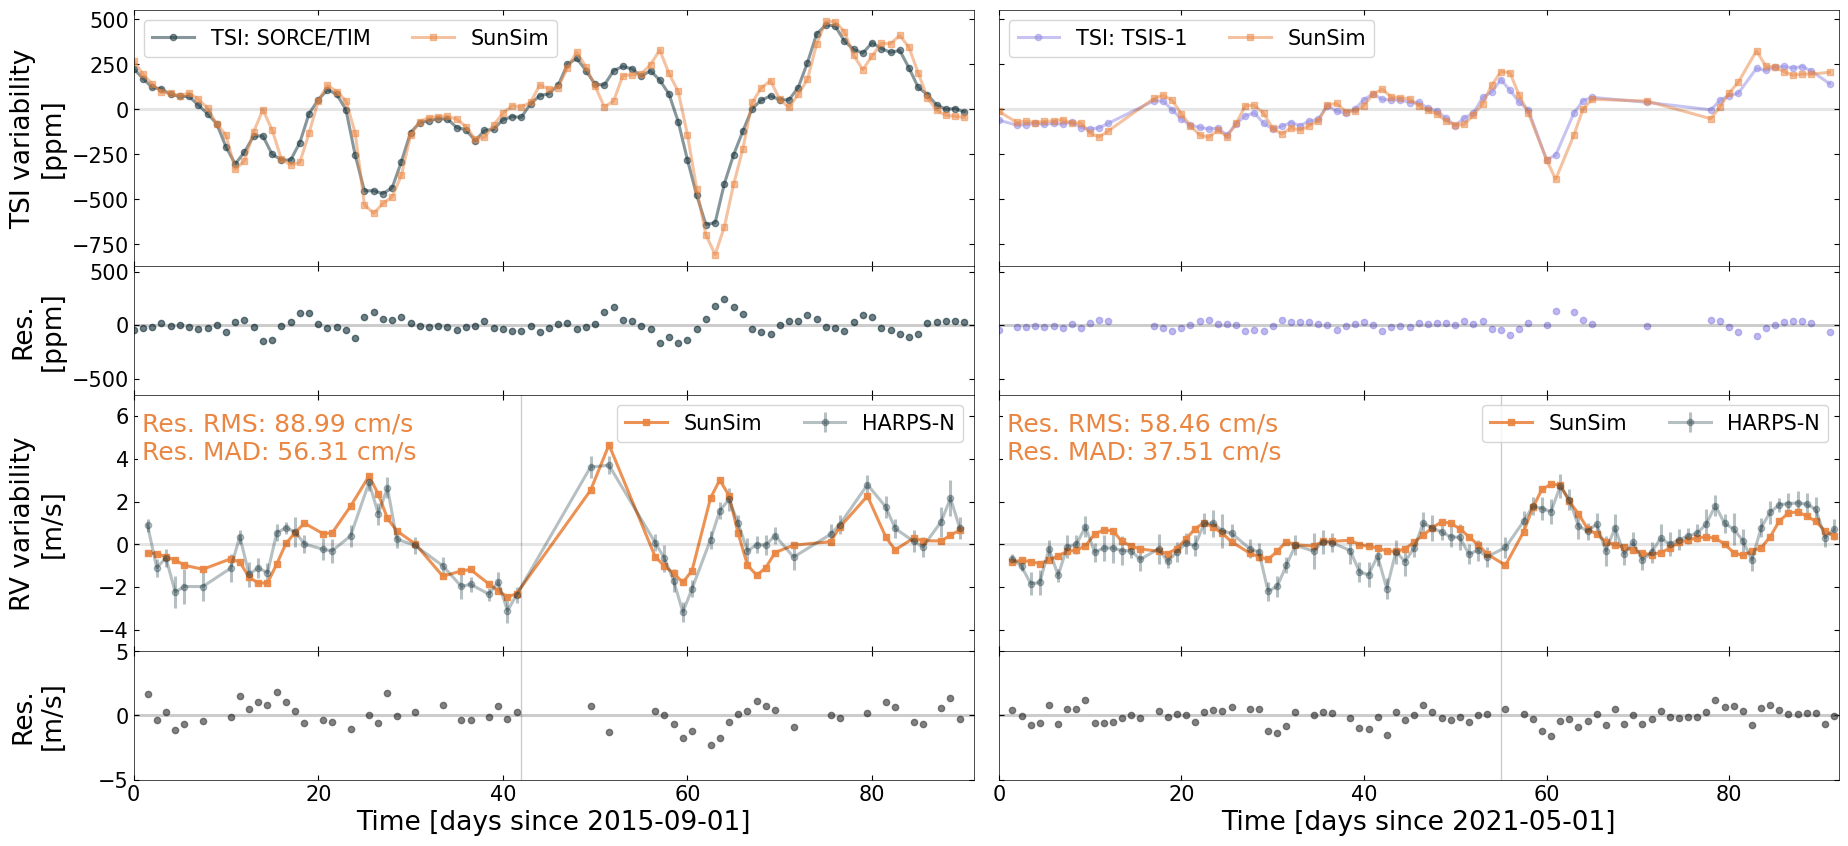

In [24]:
WINDOWS = [('2015-09-01', '2015-11-30'), ('2021-05-01', '2021-07-31')]
TSI_COLOURS = {'SORCE/TIM': obs.COLOURS['sorce'], 'TSIS-1': obs.COLOURS['tsis']}

t_all, rv_all = np.loadtxt(SIM_RV).T
_, lc_all = np.loadtxt(SIM_LC).T

with plt.rc_context({'axes.labelsize': 19, 'legend.fontsize': 15, 'lines.linewidth': 2.2, 'lines.markersize': 4.5}):
    fig, axes = plt.subplots(4, 2, sharex='col', sharey='row', figsize=(22, 10),
                             gridspec_kw={'hspace': 0, 'wspace': 0.03, 'height_ratios': [2, 1, 2, 1]})
    for col, (first, last) in zip(axes.T, WINDOWS):
        t1 = obs.jd_of_date(first) - obs.jd_of_date(ORIGIN)
        win = (t_all >= t1) & (t_all < obs.jd_of_date(last) - obs.jd_of_date(ORIGIN) + 1)
        t_w, rv_w, lc_w = t_all[win], rv_all[win], lc_all[win]
        ok = ~np.isin(t_w, LC_OUTLIERS)
        tsi = [obs.load_sorce(local_path('sorce_tsi'), ORIGIN, end=last, t_start=first),
               obs.load_tsis(local_path('tsis_tsi'), ORIGIN, end=last, t_start=first)]
        ph_w = [p for p in (obs.compare_photometry(d, t_w[ok], lc_w[ok]) for d in tsi) if p['n'] > 0]
        rv_w = obs.compare_rv(obs.load_harpsn(local_path('harpsn_sun'), ORIGIN, end=last, t_start=first),
                              t_w, rv_w, interventions=cuts)

        obs.plot_photometry_comparison(ph_w, col[0], col[1], t0=t1, colours=TSI_COLOURS, stats=False)
        obs.plot_rv_comparison(rv_w, col[2], col[3], t0=t1)
        col[2].legend(ncols=2, loc='upper right')
        # col[0].set_title('%s to %s' % (first, last))
        col[3].set_xlim(t_w.min() - t1, t_w.max() + 1 - t1)
        col[3].set_xlabel('Time [days since %s]' % first)

    axes[2, 0].set_ylim(-5, 7)
    axes[1, 0].set_ylim(-650, 550)
    axes[3, 0].set_ylim(-5, 5)
    for a in axes[:, 0]:
        a.set_ylabel(a.get_ylabel().replace(' [', '\n['))
    for a in axes[:, 1]:
        a.set_ylabel('')
    fig.align_ylabels(axes[:, 0])
    save(fig, 'all_best_fit_{}_{}'.format(*(w[0] for w in WINDOWS)))
    plt.show()

## Correlation

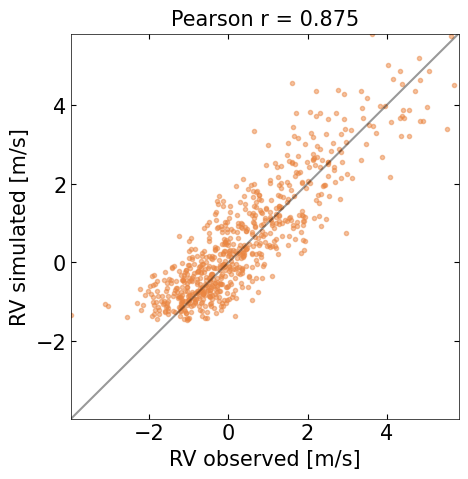

In [25]:
obs.plot_correlation(rv, label='RV')
plt.show()

## Periodograms

In [26]:
if INJECT:
    series = {'residuals': ResidualAnalysis.from_comparison(rv, 'res', name='HARPS-N - SunSim'),
              'harpsn': ResidualAnalysis.from_comparison(rv, 'obs', period_medians=True, name='HARPS-N')}

    fig, axes = plt.subplots(len(series), 1, figsize=(15, 5 * len(series)), sharex=True)
    for ax, ra in zip(axes, series.values()):
        ra.plot_periodogram(ax, mark=(ROTATION, 365))
    fig.tight_layout()
    save(fig, 'gls')
    plt.show()

## Wavelets

In [27]:
if INJECT:
    fig, axes = plt.subplots(len(series), 1, figsize=(15, 5 * len(series)), sharex=True)
    for ax, ra in zip(axes, series.values()):
        ra.plot_wavelet(ax, period_range=(2, 256))
    fig.tight_layout()
    save(fig, 'wavelet')
    plt.show()

## Injection

In [28]:
if INJECT:
    for ra in series.values():
        print(ra.name)
        ra.inject(PERIODS, AMPLITUDES, n_phases=N_PHASES, fap=FAP)

## Detection maps

In [29]:
if INJECT:
    plt.rcParams.update({"font.size": 13})
    kinds = {'FAP <= %g and |P - P_inj| / P_inj <= %g' % (FAP, PERIOD_TOL): dict(period_tol=PERIOD_TOL),
             'at the rotation (%g d) instead' % ROTATION: dict(period_tol=PERIOD_TOL, at_period=ROTATION)}

    fig, axes = plt.subplots(len(series), len(kinds), figsize=(8 * len(kinds), 6 * len(series)), squeeze=False)
    for row, ra in zip(axes, series.values()):
        for ax, (title, kw) in zip(row, kinds.items()):
            ra.plot_detection_map(ra.detection_rate(**kw), ax, title='%s: %s' % (ra.name, title))
    fig.tight_layout()
    save(fig, 'test_inj_full')
    plt.show()

In [30]:
if INJECT:
    fig, axes = plt.subplots(2, 1, figsize=(8, 12))
    for ax, name in zip(axes, ('harpsn', 'residuals')):
        ra = series[name]
        ra.plot_detection_map(ra.detection_rate(period_tol=PERIOD_TOL), ax, title=ra.name)
    # fig.tight_layout()
    save(fig, 'test_inj')
    plt.show()

In [31]:
if INJECT:
    rate_res, rate_obs = (ra.detection_rate(period_tol=PERIOD_TOL) for ra in series.values())
    ratio = np.divide(rate_res, rate_obs, out=np.full_like(rate_res, np.nan), where=rate_obs > 0)

    ax = series['residuals'].plot_detection_map(ratio, vmin=None, vmax=None, label='Detections: residuals / HARPS-N',
                                                title='|P - P_inj| / P_inj <= %g, FAP <= %g' % (PERIOD_TOL, FAP))
    save(ax.figure, 'test_inj_ratio')
    plt.show()

## Recovered semi-amplitudes and periods

In [32]:
if INJECT:
    for name, ra in series.items():
        axes = ra.plot_recovered()
        axes[0].figure.suptitle(ra.name)
        axes[0].figure.tight_layout()
        save(axes[0].figure, 'recovered_' + name)
        plt.show()